# Pytorch learning process

## pytorch 基础 如何构建一个简单的网络


In [ ]:
#pytorch 基本都要导入这些包
import torch
import torch.nn as nn
import torch.optim as optim

#这里为了简化，使用了一个简单的线性模型来拟合数据
distance = torch.tensor([[1.0], [2.0], [3.0], [4.0]])  # 输入数据 input data
time = torch.tensor([[1.0], [2.0], [3.0], [4.0]])  # 输出数据 output data

model = nn.Sequential(
    nn.Linear(1, 3),
    nn.ReLU(),
    nn.Linear(3, 1)
)

# 均方误差损失函数 mean squared error loss
loss_fn = nn.MSELoss()  

# 随机梯度下降优化器 stochastic gradient descent optimizer
optimizer = optim.SGD(model.parameters(), lr=0.01)  

for epoch in range(1000):  # 训练1000次 train for 1000 epochs
    optimizer.zero_grad()  # 清空梯度 clear the gradients
    output = model(distance)  # 前向传播 forward pass
    loss = loss_fn(output, time)  # 计算损失 compute the loss
    loss.backward()  # 反向传播 backward pass
    optimizer.step()  # 更新参数 update the parameters

    if epoch % 100 == 0:  # 每100次打印一次损失 print the loss every 100 epochs
        print(f'Epoch {epoch}, Loss: {loss.item()}')

#模型训练完成后，我们可以使用模型进行预测。下面的代码展示了如何在不计算梯度的情况下进行预测，并打印出预测结果。
with torch.no_grad():  # 在不计算梯度的情况下进行预测 make predictions without calculating gradients
    test_distance = torch.tensor([[5.0], [6.0], [7.0], [8.0]])  # 测试数据 test data
    predictions = model(test_distance)  # 预测 predictions
    print(predictions)  # 打印预测结果 print the predictions

Epoch 0, Loss: 6.377602577209473
Epoch 100, Loss: 0.039490003138780594
Epoch 200, Loss: 0.01437634602189064
Epoch 300, Loss: 0.005308407358825207
Epoch 400, Loss: 0.001966722309589386
Epoch 500, Loss: 0.0007289134082384408
Epoch 600, Loss: 0.00027005895390175283
Epoch 700, Loss: 0.00010001059126807377
Epoch 800, Loss: 3.7025158235337585e-05
Epoch 900, Loss: 1.370377231069142e-05


with 这个语法要点很重要，正常计算的时候会默认计算梯度并保存，这样不会造成混乱

## 激活函数的作用

In [4]:
model = nn.Sequential(
    nn.Linear(1, 3),
    nn.ReLU(),
    nn.Linear(3, 1)
)
#三个神经元，经过激活函数，就能拟合出复杂的多段函数


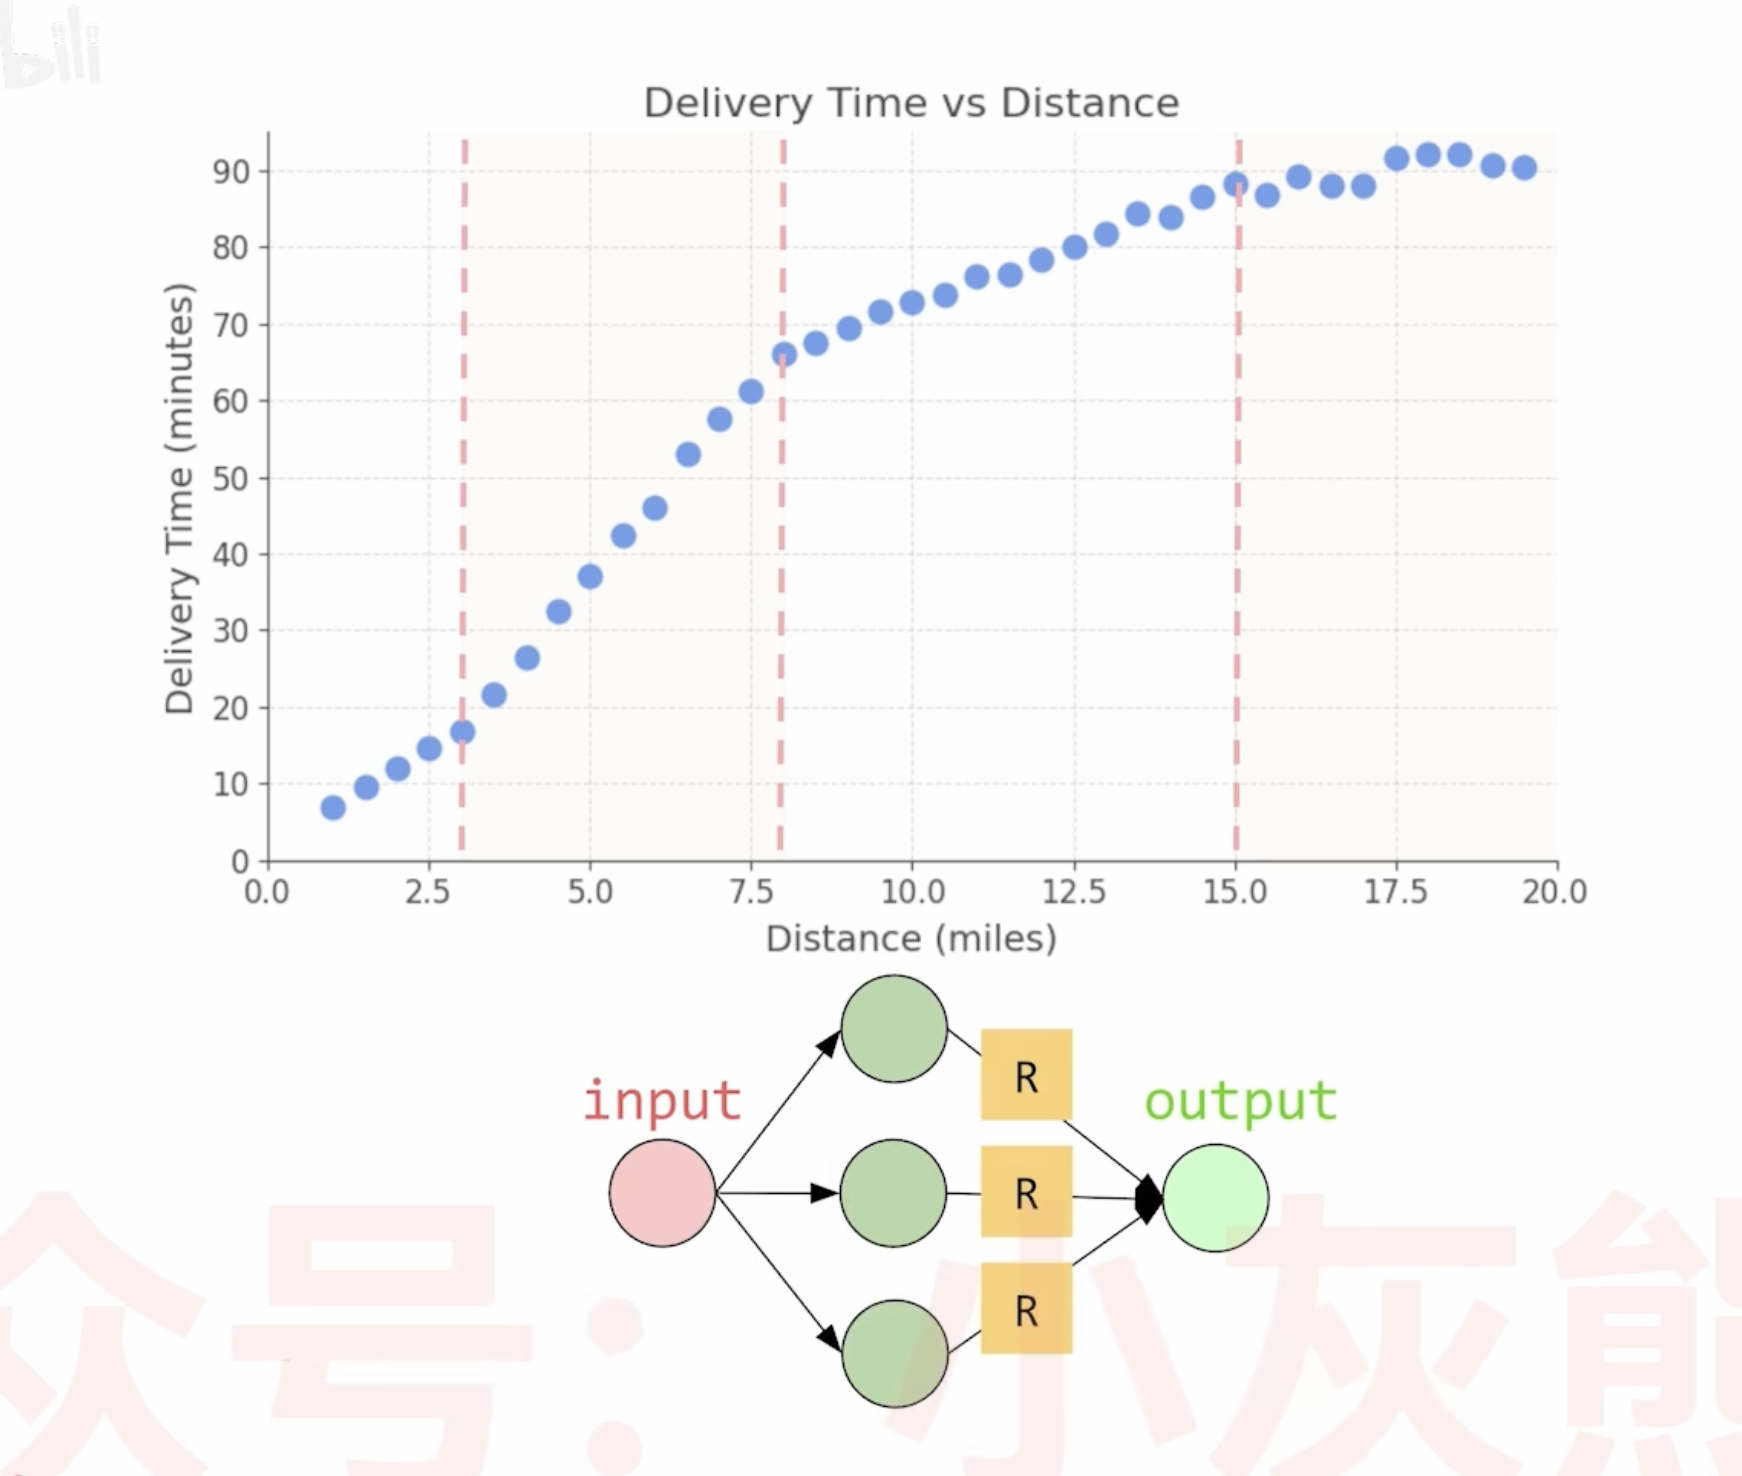

In [42]:
distance = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
print(distance)
print(distance.shape)

tensor([[1.],
        [2.],
        [3.],
        [4.]])
torch.Size([4, 1])


In [11]:
distance = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
print(distance)
print(distance.shape)
simple_model = nn.Linear(1, 1)
output = simple_model(distance)
print(output.shape)

tensor([[1.],
        [2.],
        [3.],
        [4.]])
torch.Size([4, 1])
torch.Size([4, 1])


In [15]:
float_tensor = torch.tensor([1.0, 2.0, 3.0, 4.0])
print(float_tensor)
print(float_tensor.dtype)  # Output: torch.float32 默认是32位小数
mixed_tensor = torch.tensor([1.0, 2, 3.0, 4])  # 混合类型
print(mixed_tensor)
print(mixed_tensor.dtype)  # Output: torch.float32会自动将整数转换为浮点数

tensor([1., 2., 3., 4.])
torch.float32
tensor([1., 2., 3., 4.])
torch.float32


In [16]:
#如何创建tensor
import numpy as np
# Create a tensor from a NumPy array
np_array = np.array([[1, 2], [3, 4]])
tensor_from_np = torch.from_numpy(np_array)
print(tensor_from_np)
#这种方式是内存共享的，修改tensor_from_np会影响np_array
zero_tensor = torch.zeros((2, 3))  # Create a tensor filled with zeros
one_tensor = torch.ones((2, 3))    # Create a tensor filled with ones
rand_tensor = torch.rand((2, 3))   # Create a tensor with random values between 0 and 1 

tensor([[1, 2],
        [3, 4]])


In [22]:
single_element_tensor = torch.tensor(5.0)  # Create a tensor with a single element
print(single_element_tensor.shape)  # Output: torch.Size([]), which indicates a scalar tensor这是标量
with_batch=single_element_tensor.unsqueeze(0)  # Add a batch dimension
print(with_batch.shape)  # Output: torch.Size([1]), which indicates a tensor with
ready_for_model=with_batch.unsqueeze(1)  # Add a batch dimension
print(ready_for_model.shape)  # Output: torch.Size([1, 1]), which indicates a tensor with
ready_for_model=ready_for_model.squeeze()  # remove the batch dimension
print(ready_for_model.shape)  # Output: torch.Size([]), which indicates a scalar

torch.Size([])
torch.Size([1])
torch.Size([1, 1])
torch.Size([])


In [26]:
predictions = torch.tensor([0.1, 0.2, 0.3, 0.4])    
first = predictions[0]  # Access the first element
print(first)  # Output: tensor(0.1000)
first_three = predictions[:3]  # Access the first three elements
print(first_three)  # Output: tensor([0.1000, 0.2000, 0.3000])
first = first.item()  # Convert to a Python float
print(first)  # Output: 0.1

tensor(0.1000)
tensor([0.1000, 0.2000, 0.3000])
0.10000000149011612


In [34]:
product_tensor = torch.tensor([[1, 2], [3, 4]])
print(product_tensor.shape)  # Output: torch.Size([2, 2]), which indicates
print(product_tensor[:1].shape)
print(product_tensor[1:])
print(product_tensor[:, 0])  # Access the first column
print(product_tensor[:, 0].shape)  # Access the second column

torch.Size([2, 2])
torch.Size([1, 2])
tensor([[3, 4]])
tensor([1, 3])
torch.Size([2])


# 数据如何从磁盘到训练

In [ ]:
#transforms is a module in the torchvision library that provides common image transformations for data preprocessing and augmentation. It is often used when working with image datasets in deep learning tasks, such as image classification or object detection.
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torch.utils.data as data
#数据加载进来，要做的处理
transform = transforms.Compose([
    transforms.toTensor(),  # Convert PIL Image or numpy.ndarray to tensor scale [0, 1]
    transforms.Normalize((mean,), (std,))  # Normalize the tensor  centering them around zero and scaling them to have unit variance. The mean and std are typically calculated from the training dataset.
])
#加载哪个数据集
#root specifies the directory where the dataset will be stored or loaded from. If the dataset is not found in this directory, it will be downloaded automatically.
#train indicates whether to load the training set (True) or the test set (False).
dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
#数据加载器
dataloader = data.DataLoader(dataset, batch_size=32, shuffle=True)

## 未来让网络结构更可控，引入下面这种结构

In [ ]:
#定义一个简单的神经网络模型，用类的方式定义模型，继承nn.Module
class exampleModel(nn.Module):
    def __init__(self):
        super(exampleModel, self).__init__()
        self.fc1 = nn.Linear(784, 128)  # Fully connected layer from 784 input features to 128 output features
        self.fc2 = nn.Linear(128, 10)   # Fully connected layer from 128 input features to 10 output features (for 10 classes)

    def forward(self, x):
        x = x.view(-1, 784)  # Flatten the input tensor to shape (batch_size, 784)
        x = torch.relu(self.fc1(x))  # Apply ReLU activation after the first layer
        x = self.fc2(x)  # Output layer
        return x
#怎样传入数据？
# 创建模型实例
model = exampleModel()

# 传入数据
input_data = torch.randn(64, 784)  # Create a random tensor of shape (64, 784)
output = model(input_data)  # Pass the input through the model


In [ ]:
model.eval()  # Set the model to evaluation mode
with torch.no_grad():  # Disable gradient calculation for inference
    correct = 0
    total = 0
    for images, labels in dataloader:  # Iterate over the data in the dataloader
        outputs = model(images)  # Get the model's predictions for the images
        _, predicted = torch.max(outputs.data, 1)  # Get the index of the max log-probability
        total += labels.size(0)  # Update the total number of samples
        correct += (predicted == labels).sum().item()  # Update the number of correct predictions
    accuracy = correct / total  # Calculate the accuracy
    print(f'Accuracy: {accuracy * 100:.2f}%')  # Print the accuracy as a percentage
    
model.train()  # Set the model back to training mode

# loss function
分类任务用交叉熵 回归任务用mse
接下来算梯度更新 更新的算法有 sgd adam

In [ ]:
# Define the loss function for multi-class classification
loss_cross = nn.CrossEntropyLoss()  
# Define the loss function for regression tasks
loss_mse = nn.MSELoss()  

loss = loss_cross(outputs, labels)  # Compute the loss using CrossEntropyLoss
loss.backward()  # Perform backpropagation to compute gradients

#optimizer 就选adam 通常更快更可靠
optimizer = optim.SGD(model.parameters(), lr=0.01)  # Define the optimizer (Stochastic Gradient Descent)
optimizer = optim.Adam(model.parameters(), lr=0.001)  # Define the optimizer (Adam)
update = optimizer.step()  # Update the model parameters using the optimizer

# 设备管理

In [3]:
import torch
print(torch.cuda.is_available()) # 检测CUDA，Mac上会输出False
print(torch.backends.mps.is_available()) # 检测苹果MPS，Mac硅芯片会输出True
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")  # Set the device to CUDA, MPS, or CPU

False
True


In [ ]:
model = exampleModel().to(device)  # Move the model to the selected device (GPU, MPS, or CPU)
for target, data in dataloader:
    data, target = data.to(device), target.to(device)  # Move the data and target to the selected device
    optimizer.zero_grad()  # Clear the gradients
    output = model(data)  # Forward pass
    loss = loss_fn(output, target)  # Compute the loss
    loss.backward()  # Backward pass
    optimizer.step()  # Update the model parameters